# 02 · Forecast evaluation

Analysis of the walk-forward out-of-sample predictions written by `fr-power train` (`data/processed/predictions.parquet`). Nothing is retrained here except the single illustrative LightGBM fit used for feature importance at the end.

All models are scored on the same hours (those where every model has a forecast).

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from fr_power.config import load_config
from fr_power.evaluation import common_rows, dm_table, mae_by_year, point_metrics
from fr_power.features import TARGET, feature_columns
from fr_power.models import LightGBMForecaster

plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3})

cfg = load_config("../configs/default.yaml")
matrix = pd.read_parquet("../data/processed/feature_matrix.parquet")
predictions = pd.read_parquet("../data/processed/predictions.parquet")
actual = matrix[TARGET]
df = common_rows(actual, predictions)
print(f"{len(df):,} out-of-sample hours, {df.index.min():%Y-%m-%d} -> {df.index.max():%Y-%m-%d}")

51,224 out-of-sample hours, 2020-12-31 -> 2026-11-15


## Headline metrics (EUR/MWh)

`rmae_vs_naive` < 1 means the model beats the naive benchmark.

In [2]:
point_metrics(actual, predictions).round(2)

,mae,rmse,median_ae,rmae_vs_naive
naive,29.41,53.23,16.93,1.00
lasso,22.90,40.09,14.99,0.78
lightgbm,32.46,58.68,17.21,1.10


## Accuracy over time

Absolute errors scale with the price level, so the crisis years dominate any full-sample average. The relative ranking of models is the more stable signal.

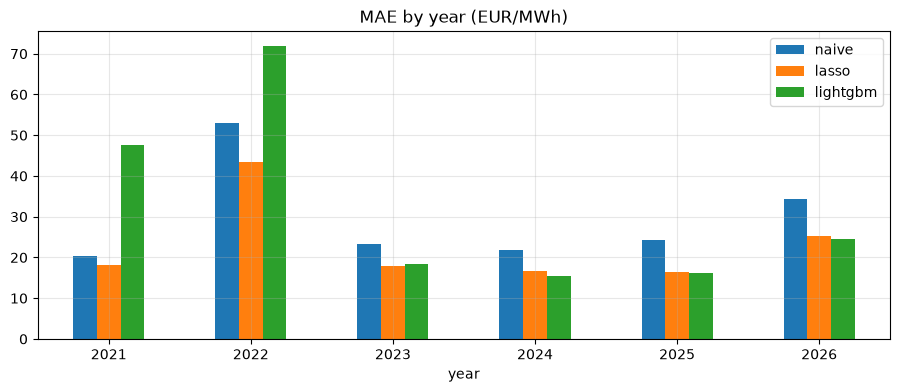

,naive / naive,lasso / naive,lightgbm / naive
year,,,
2021,1.0,0.89,2.35
2022,1.0,0.82,1.36
2023,1.0,0.76,0.78
2024,1.0,0.77,0.71
2025,1.0,0.68,0.66
2026,1.0,0.74,0.72


In [3]:
yearly = mae_by_year(actual, predictions)
ax = yearly.plot.bar(rot=0, title="MAE by year (EUR/MWh)")
plt.show()
yearly.div(yearly["naive"], axis=0).round(2).rename(columns=lambda c: f"{c} / naive")

## Diebold–Mariano tests

Pairwise tests on the daily-averaged absolute-error differential. A negative statistic with p < 0.05 means `model_a` is significantly more accurate.

In [4]:
dm_table(actual, predictions).round(4)

,model_a,model_b,dm_stat,p_value
0,naive,lasso,13.5371,0.0000
1,naive,lightgbm,-3.5205,0.0004
2,lasso,lightgbm,-12.8387,0.0000


## Error by hour of day

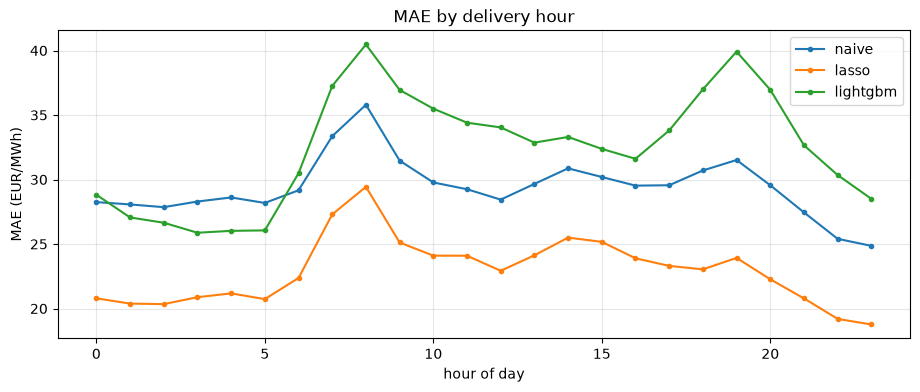

In [5]:
errors = df[predictions.columns].sub(df["actual"], axis=0).abs()
ax = errors.groupby(errors.index.hour).mean().plot(marker=".")
ax.set(xlabel="hour of day", ylabel="MAE (EUR/MWh)", title="MAE by delivery hour")
plt.show()

## Two sample weeks: winter and summer of the last full year

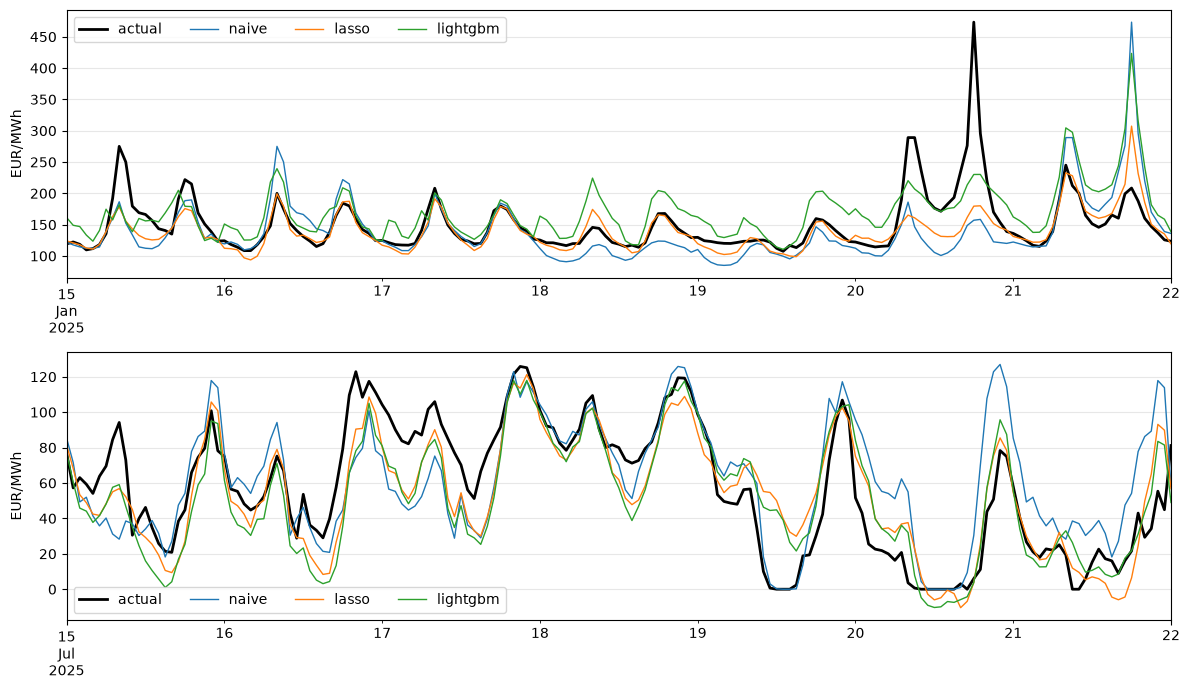

In [6]:
last_year = df.index.max().year - 1
fig, axes = plt.subplots(2, 1, figsize=(12, 7))
for ax, start in zip(axes, [f"{last_year}-01-15", f"{last_year}-07-15"]):
    t0 = pd.Timestamp(start, tz=df.index.tz)
    week = df.loc[t0 : t0 + pd.Timedelta(days=7)]
    week["actual"].plot(ax=ax, color="black", linewidth=2, label="actual")
    week[predictions.columns].plot(ax=ax, linewidth=1)
    ax.set(ylabel="EUR/MWh", xlabel="")
    ax.legend(ncol=4)
plt.tight_layout()
plt.show()

## What drives LightGBM?

One fit on the last two years of data (not walk-forward, illustration only); importance = total split gain.

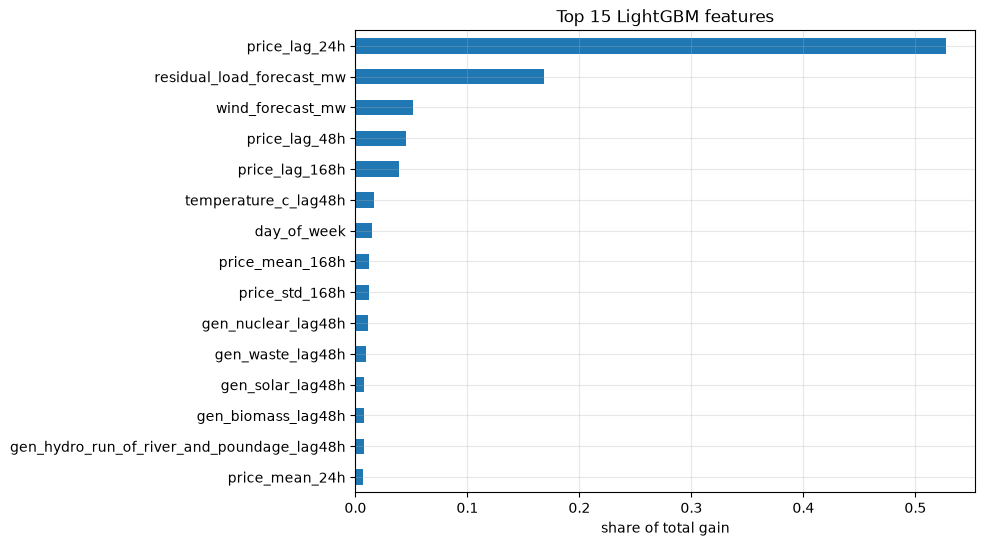

In [7]:
recent = matrix[matrix.index >= matrix.index.max() - pd.Timedelta(days=730)].dropna(subset=[TARGET])
model = LightGBMForecaster(cfg.models.lightgbm, cfg.random_seed)
model.fit(recent[feature_columns(matrix)], recent[TARGET])
importance = pd.Series(
    model.model_.booster_.feature_importance("gain"), index=feature_columns(matrix)
).sort_values()
ax = (importance / importance.sum()).tail(15).plot.barh(figsize=(8, 6))
ax.set(xlabel="share of total gain", title="Top 15 LightGBM features")
plt.show()